In [1]:
import torch
from google.colab import drive
import os

drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/aiffel
os.chdir('/content/drive/MyDrive/aiffel')
os.environ["HF_HOME"] = "/root/.cache/huggingface"

print("GPU 사용 가능 여부:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("연결된 GPU 이름:", torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU 사용 가능 여부: True
연결된 GPU 이름: Tesla T4


# 사내 데이터 QLoRA 파인튜닝 실습

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 들어가며

이 레슨에서는 사내 문서로 인스트럭션 데이터셋을 만들어 품질을 검증하고 QLoRA로 학습한 뒤 전후를 정량 비교합니다.

목표는 **모델을 바꾸는 것**이 아니라 **바꿔서 무엇이 좋아지고 무엇이 나빠졌는지 재는 것**입니다.

### 실행 환경

| 항목 | 내용 |
|---|---|
| 런타임 | GPU 런타임. 실습 환경 GPU(T4, VRAM 16GB)에서 끝까지 돌아갑니다 |
| 필요한 키 | 없습니다. 게이트 없는 공개 모델만 씁니다 |
| 올리는 모델 | Qwen2.5-3B-Instruct 4bit 한 개. 선택 트랙 4에서 fp16 한 개를 더 올립니다 |
| 디스크 | 베이스 모델 약 6GB, 어댑터 120MB 남짓 |
| 오류가 났을 때 | 셀이 오류로 멈춘 뒤 VRAM이 돌아오지 않으면 런타임을 다시 시작하고 Step 0~5를 다시 실행합니다 |

| 오래 걸리는 셀 | 실습 환경 기준 대략 |
|---|---|
| Step 4 기준선 평가 (두 조건 × 20건) | 6~10분 |
| Step 5 학습 (700건, 2에폭) | 25~40분 |
| Step 6 전후 평가 (두 조건 × 20건) | 6~10분 |
| 선택 트랙 1 (설정 네 개 학습) | 30~45분 |

🖥 **로컬 작업** 표시가 붙은 곳은 **실습 환경에서는 흉내만 내고 사내에서는 달라지는 부분**입니다. 실습 데이터를 사내 데이터로 바꾸는 자리, 민감 정보 규칙을 사내 규칙으로 바꾸는 자리, 어댑터를 사내 저장소에 두는 자리입니다.

실습 셀(코드가 비어 있고 바로 아래 '정답 보기'가 붙은 셀)의 저장된 출력은 정답 코드를 넣고 실행한 결과입니다. 코드를 채우기 전에 그대로 실행하면 다른 결과가 나옵니다.

## Step 0 : 환경 준비

판본을 고정합니다. 이 분야는 메이저 판이 올라가면 인자 이름이 바뀌어 예제가 통째로 안 돌기도 합니다. `transformers` 5에서는 `warmup_ratio`가 없어졌고 `torch_dtype`이 `dtype`으로 바뀌었습니다.

In [2]:
!pip install -q "transformers>=5.17,<6" "accelerate>=1.15,<2" "bitsandbytes>=0.50,<0.51"
!pip install -q "peft>=0.21,<0.22" "trl>=1.13,<2" "datasets>=5.0,<6"
# 실습 환경에 미리 깔린 torchao 는 PEFT 와 버전이 맞지 않습니다. 이 레슨은 쓰지 않으므로 지웁니다
!pip uninstall -y -q torchao

# 아래 임포트 셀에서 오류가 나면 [런타임] - [세션 다시 시작] 을 한 번 누르고 이 셀 아래부터 다시 실행하십시오.
# 설치 로그 끝의 pyarrow 충돌 안내는 실습 환경의 다른 패키지 이야기라 무시해도 됩니다

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 65.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 15.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 47.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [3]:
# 실제로 무엇이 깔렸는지 찍어 둡니다. 나중에 결과가 달라지면 여기부터 봅니다
import importlib.metadata as md

for name in ["torch", "transformers", "peft", "trl", "datasets", "accelerate", "bitsandbytes"]:
    try:
        print(f"{name:<14} {md.version(name)}")
    except md.PackageNotFoundError:
        print(f"{name:<14} 설치 안 됨")

torch          2.11.0+cu130
transformers   5.18.0
peft           0.21.1
trl            1.15.0
datasets       5.1.0
accelerate     1.15.0
bitsandbytes   0.50.2


In [4]:
import gc, json, random, re, time
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging
import logging

# 라이브러리의 안내 경고를 끕니다. 켜 두면 평가·학습 출력에서 결과가 경고 사이에 묻힙니다
hf_logging.set_verbosity_error()         # 생성 설정 안내(max_length 등)
hub_logging.set_verbosity_error()        # '토큰 없이 요청 중' 안내
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)   # 8bit 곱셈의 dtype 변환 경고

random.seed(42)
torch.manual_seed(42)

HAS_GPU = torch.cuda.is_available()
USE_BF16 = torch.cuda.is_bf16_supported(including_emulation=False)   # bf16 회로가 있는 GPU 만 True. 흉내만 내는 GPU(T4)는 False 가 되어 아래에서 fp16 으로 학습합니다
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16


def vram_gb(peak=False):
    """VRAM 사용량(GB). GPU 가 없으면 0.0 을 돌려주고 멈추지 않습니다"""
    if not HAS_GPU:
        return 0.0
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


if HAS_GPU:
    prop = torch.cuda.get_device_properties(0)
    print(f"GPU : {prop.name} / VRAM {prop.total_memory / 1e9:.1f} GB")
    print(f"bf16 지원 : {USE_BF16}  (지원하면 bf16, 아니면 fp16 으로 학습합니다)")
else:
    print("GPU 런타임이 아닙니다. [런타임] - [런타임 유형 변경] 에서 GPU 를 고르고 다시 실행하십시오.")

GPU : Tesla T4 / VRAM 15.6 GB
bf16 지원 : False  (지원하면 bf16, 아니면 fp16 으로 학습합니다)


`USE_BF16`은 값을 코드에 직접 적지 않고 **실행 중인 GPU에서 읽어 옵니다.** 실습 환경은 그날 배정에 따라 GPU 종류가 달라질 수 있어서 `fp16=True`로 고정해 두면 bf16이 되는 GPU에서 굳이 손해를 봅니다.

`including_emulation=False`를 준 이유는 이렇습니다. bf16 회로가 없는 GPU도 소프트웨어로 흉내는 낼 수 있어서, 그냥 물어보면 True라고 답합니다. 흉내 내는 bf16으로 학습하면 fp16보다 몇 배 느립니다. 회로가 있는 GPU에서만 bf16을 쓰도록 이 인자를 줍니다.

## Step 1 : 태스크 정의와 목표 설정

**사내 회의록을 표준 양식으로 정리하는 작업**을 자동화합니다.

이론 레슨 1장의 판단 기준을 적용해 봅니다. 이 태스크는 파인튜닝이 적절합니까?

- 사실 정보를 정확히 답해야 하는가 → 아니오. 입력에 주어진 내용만 정리합니다  
- 형식이 정해져 있는가 → 예. 사내 표준 양식이 있습니다  
- 양식이 자주 바뀌는가 → 아니오. 안정적입니다  
- 지시문이 긴가 → 예. 양식 규약이 여러 개입니다

형식 학습이고 안정적이며 프롬프트로 하면 지시문이 길어지므로 **파인튜닝에 맞는 태스크입니다.**

In [5]:
# 시스템 프롬프트. 학습할 때와 추론할 때 똑같은 것을 씁니다
SYSTEM_PROMPT = ("당신은 사내 문서를 정리하는 어시스턴트입니다. "
                 "답변은 반드시 한국어로 작성합니다.")

# 사내 표준 양식. 이것이 프롬프트로 매번 들어가야 하는 내용입니다
FORMAT_GUIDE = """[회의록 정리 표준 양식]
아래 형식을 정확히 지켜 작성하세요.

## 회의 개요
- 일시 :
- 참석 :
- 주제 :

## 결정 사항
1. (결정 내용) / 담당: (담당자) / 기한: (기한)

## 논의 사항
- (결론이 나지 않은 안건)

## 후속 조치
- (다음 회의까지 할 일)

규칙
1. 결정 사항에는 반드시 담당자와 기한을 표기한다. 언급이 없으면 '미정'으로 적는다.
2. 결정된 것과 논의만 된 것을 구분한다.
3. 원문에 없는 내용을 추가하지 않는다.
4. 각 항목은 한 줄로 간결하게 작성한다.
5. 결정 사항이 하나도 없으면 '1. 없음 / 담당: 미정 / 기한: 미정' 한 줄만 적는다."""

print(f"양식 지시문 길이 : {len(FORMAT_GUIDE)}자")

양식 지시문 길이 : 345자


시스템 프롬프트를 따로 둔 데는 이유가 있습니다.

첫째, **출력 언어를 고정합니다.** Qwen 계열은 한국어로 물어도 중국어나 영어로 새는 일이 있는데 시스템 프롬프트에 한 줄을 넣어 두면 크게 줄어듭니다.

둘째, **학습과 추론의 형태를 맞춥니다.** 학습 데이터에는 시스템 프롬프트가 없는데 추론할 때만 넣으면 모델이 처음 보는 형태를 받습니다. Step 5에서 학습 데이터를 만들 때 같은 문장을 넣습니다.

## Step 2 : 데이터셋 만들기

사내 회의록을 실습 레슨에 올릴 수 없으므로 이론 레슨 4.3절의 **세 가지 길** 중 **길 2**(규칙으로 만든다)만 씁니다. 길 3(다른 모델로 만들기)은 LLM 호출이 한 번 더 필요하고 이론 4.5절의 두 함정을 검사하는 절차가 따로 붙어서 쓰지 않습니다.

🖥 **로컬 작업** : 사내에서는 순서가 반대입니다. **길 1(기존 회의록)로 뼈대를 잡고** 비어 있는 상황만 길 2로 채웁니다. 아래 `make_raw_minutes`와 `make_gold_output`이 그 자리입니다.

길 2만 쓰면 **다양성이 낮습니다.** 템플릿 열 개로 1,000건을 만들면 실질적으로 열 건짜리 데이터셋입니다. 그래서 주제·참석자·안건 수·문장을 조합해 흔들고 Step 3에서 실제로 쏠렸는지 세어 봅니다.

In [6]:
# 회의록 원문 생성기. 다양성을 위해 요소를 조합합니다
TOPICS = ["신규 기능 출시", "인프라 비용 절감", "채용 계획", "보안 감사 대응",
          "고객 이슈 처리", "분기 실적 검토", "협력사 계약", "교육 프로그램 개편"]
PEOPLE = ["김서준", "이지우", "박민재", "최유나", "정하윤", "강도현", "윤서아", "임태호"]
TEAMS = ["개발1팀", "개발2팀", "인프라팀", "기획팀", "영업팀", "보안팀", "인사팀"]
ACTIONS = ["일정을 확정했다", "예산을 승인했다", "담당을 지정했다", "보류하기로 했다",
           "추가 검토가 필요하다는 의견이 나왔다", "다음 회의에서 재논의하기로 했다"]


def make_raw_minutes(seed):
    rnd = random.Random(seed)
    topic = rnd.choice(TOPICS)
    attendees = rnd.sample(PEOPLE, rnd.randint(3, 5))
    month, day = rnd.randint(1, 12), rnd.randint(1, 28)

    lines = [f"{month}월 {day}일 {topic} 관련 회의. 참석자 {', '.join(attendees)}."]
    n_items = rnd.randint(2, 4)
    decided, discussed = [], []

    for i in range(n_items):
        act = rnd.choice(ACTIONS)
        owner = rnd.choice(attendees)
        team = rnd.choice(TEAMS)
        if "보류" in act or "검토" in act or "재논의" in act:
            lines.append(f"- {topic} 관련 {i+1}번 안건은 {act}. {team} 의견 수렴 필요.")
            discussed.append((f"{topic} {i+1}번 안건", act))
        else:
            deadline = f"{month+1 if month < 12 else 1}월 {rnd.randint(1,28)}일"
            lines.append(f"- {i+1}번 안건 {act}. {owner}이 {deadline}까지 진행.")
            decided.append((f"{i+1}번 안건 {act}", owner, deadline))

    if rnd.random() < 0.5:
        lines.append(f"- 다음 회의는 {month+1 if month < 12 else 1}월 {rnd.randint(1,28)}일.")

    return {
        "raw": "\n".join(lines),
        "meta": {"date": f"{month}월 {day}일", "attendees": attendees,
                 "topic": topic, "decided": decided, "discussed": discussed},
    }


sample = make_raw_minutes(0)
print(sample["raw"])

7월 26일 협력사 계약 관련 회의. 참석자 김서준, 박민재, 정하윤, 최유나.
- 협력사 계약 관련 1번 안건은 보류하기로 했다. 영업팀 의견 수렴 필요.
- 2번 안건 예산을 승인했다. 박민재이 8월 5일까지 진행.
- 3번 안건 일정을 확정했다. 정하윤이 8월 23일까지 진행.


In [7]:
# 정답 출력을 규칙 기반으로 생성합니다
# 실무에서는 사람이 작성한 기존 회의록을 정답으로 씁니다

def make_gold_output(meta):
    lines = ["## 회의 개요",
             f"- 일시 : {meta['date']}",
             f"- 참석 : {', '.join(meta['attendees'])}",
             f"- 주제 : {meta['topic']}",
             "",
             "## 결정 사항"]
    if meta["decided"]:
        for i, (what, owner, when) in enumerate(meta["decided"], 1):
            lines.append(f"{i}. {what} / 담당: {owner} / 기한: {when}")
    else:
        lines.append("1. 없음 / 담당: 미정 / 기한: 미정")

    lines += ["", "## 논의 사항"]
    if meta["discussed"]:
        for what, act in meta["discussed"]:
            lines.append(f"- {what}: {act}")
    else:
        lines.append("- 없음")

    lines += ["", "## 후속 조치"]
    if meta["discussed"]:
        lines.append(f"- {meta['discussed'][0][0]} 재검토 및 의견 수렴")
    else:
        lines.append("- 결정 사항 이행 점검")

    return "\n".join(lines)


print(make_gold_output(sample["meta"]))

## 회의 개요
- 일시 : 7월 26일
- 참석 : 김서준, 박민재, 정하윤, 최유나
- 주제 : 협력사 계약

## 결정 사항
1. 2번 안건 예산을 승인했다 / 담당: 박민재 / 기한: 8월 5일
2. 3번 안건 일정을 확정했다 / 담당: 정하윤 / 기한: 8월 23일

## 논의 사항
- 협력사 계약 1번 안건: 보류하기로 했다

## 후속 조치
- 협력사 계약 1번 안건 재검토 및 의견 수렴


In [8]:
# 데이터셋 생성
INSTRUCTION = "다음 회의록 원문을 사내 표준 양식으로 정리하세요."

def build_dataset(n, start=0):
    rows = []
    for i in range(start, start + n):
        m = make_raw_minutes(i)
        rows.append({
            "instruction": INSTRUCTION,
            "input": m["raw"],
            "output": make_gold_output(m["meta"]),
            "meta": m["meta"],
        })
    return rows


train_rows = build_dataset(700, start=0)
valid_rows = build_dataset(80, start=10000)
test_rows = build_dataset(40, start=20000)

print(f"학습 {len(train_rows)}건, 검증 {len(valid_rows)}건, 테스트 {len(test_rows)}건")

학습 700건, 검증 80건, 테스트 40건


데이터를 나눌 때 **시드 구간을 완전히 분리**했습니다. `start`를 다르게 주어 학습과 테스트에 같은 회의록이 절대 나오지 않게 했습니다.

학습에 쓴 회의록이 테스트에 섞이는 것을 **데이터 누수**라고 합니다. 누수가 있으면 모델이 이미 본 문제로 시험을 보는 셈이라 점수를 믿을 수 없습니다.

## Step 3 : 데이터 품질 검증

이론 레슨 4.4절의 센서를 코드로 옮깁니다. 표의 일곱 항목 중 **여섯 개를 기계로** 검사하고 다양성은 세어서 사람이 봅니다.

| 이론 4.4절 항목 | 이 레슨에서 |
|---|---|
| 형식 일관성 | `validate_dataset`의 `format_fail` |
| 규칙 준수 | `rule_fail` |
| 중복 | `duplicates` |
| 길이 분포 | `len_min`, `len_max`, `len_mean` |
| 사실 정확성 | `fact_fail` (출력을 원문과 대조) |
| 민감 정보 | `pii_fail` (연락처·이메일·계좌·사번 패턴) |
| 다양성 | 다양성 확인 셀 |

In [9]:
# 실습 : 데이터셋 품질 검증 함수를 완성하세요
# 여섯 항목을 모두 채웁니다. 형식, 규칙, 중복, 길이, 사실 정확성, 민감 정보

REQUIRED_SECTIONS = ["## 회의 개요", "## 결정 사항", "## 논의 사항", "## 후속 조치"]

# 🖥 로컬 작업 : 사내 규칙에 맞게 고쳐 쓰십시오. 사번 형식과 계좌 형식이 회사마다 다릅니다
PII_PATTERNS = {
    "전화번호": r"01[016789][-\s.]?\d{3,4}[-\s.]?\d{4}",
    "이메일": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "계좌번호": r"\b\d{3,6}-\d{2,6}-\d{2,6}\b",
    "사번": r"\b[A-Z]{1,3}\d{5,8}\b",
}
NUM = re.compile(r"\d+")


def decided_items(out):
    """결정 사항 블록의 번호 붙은 줄들. 블록을 못 찾으면 None"""
    if "## 결정 사항" not in out or "## 논의 사항" not in out:
        return None
    block = out.split("## 결정 사항")[1].split("## 논의 사항")[0]
    return [l.strip() for l in block.strip().split("\n") if re.match(r"^\d+\.", l.strip())]


def fact_fail_reasons(out, raw):
    """이론 4.4절 '사실 정확성'. 출력에만 있는 숫자와 담당자를 찾습니다"""
    reasons = []
    body = re.sub(r"(?m)^\s*\d+\.\s", "", out)          # 번호 매기기는 원문에 없는 숫자입니다
    raw_nums = set(NUM.findall(raw))
    for n in sorted(set(NUM.findall(body))):
        if n not in raw_nums:
            reasons.append(f"원문에 없는 숫자 {n}")
    for owner in re.findall(r"담당:\s*([^/\n]+)", out):
        owner = owner.strip()
        if owner != "미정" and owner not in raw:
            reasons.append(f"원문에 없는 담당자 {owner}")
    return reasons

def pii_hits(text):
    """이론 4.4절 '민감 정보'"""
    return [name for name, pat in PII_PATTERNS.items() if re.search(pat, text)]

def validate_dataset(rows):
    report = {"total": len(rows), "format_fail": [], "rule_fail": [], "fact_fail": [],
              "pii_fail": [], "duplicates": 0, "len_min": 0, "len_max": 0}

    seen = set()
    lengths = []

    for i, r in enumerate(rows):
        out, raw = r["output"], r["input"]
        lengths.append(len(out))

        # 1) 형식 일관성
        if not all(s in out for s in REQUIRED_SECTIONS):
            report["format_fail"].append(i)

        # 2) 규칙 준수 : 결정 사항 블록의 각 항목에 담당과 기한
        items = decided_items(out)
        if not items or not all(("담당:" in it and "기한:" in it) for it in items):
            report["rule_fail"].append(i)

        # 3) 중복
        if raw in seen:
            report["duplicates"] += 1
        seen.add(raw)

        # 4) 사실 정확성 : 원문 대조
        if fact_fail_reasons(out, raw):
            report["fact_fail"].append(i)

        # 5) 민감 정보 : 원문과 출력을 함께 봅니다
        if pii_hits(raw) or pii_hits(out):
            report["pii_fail"].append(i)

    report["len_min"] = min(lengths)
    report["len_max"] = max(lengths)
    report["len_mean"] = int(np.mean(lengths))
    return report


rep = validate_dataset(train_rows)
LISTS = ("format_fail", "rule_fail", "fact_fail", "pii_fail")
print(json.dumps({k: v for k, v in rep.items() if k not in LISTS},
                 ensure_ascii=False, indent=2))
print("  ".join(f"{k} {len(rep[k])}건" for k in LISTS))

{
  "total": 700,
  "duplicates": 0,
  "len_min": 179,
  "len_max": 316,
  "len_mean": 236
}
format_fail 0건  rule_fail 0건  fact_fail 0건  pii_fail 0건


<details>
<summary>정답 보기</summary>

```python
def fact_fail_reasons(out, raw):
    """이론 4.4절 '사실 정확성'. 출력에만 있는 숫자와 담당자를 찾습니다"""
    reasons = []
    body = re.sub(r"(?m)^\s*\d+\.\s", "", out)          # 번호 매기기는 원문에 없는 숫자입니다
    raw_nums = set(NUM.findall(raw))
    for n in sorted(set(NUM.findall(body))):
        if n not in raw_nums:
            reasons.append(f"원문에 없는 숫자 {n}")
    for owner in re.findall(r"담당:\s*([^/\n]+)", out):
        owner = owner.strip()
        if owner != "미정" and owner not in raw:
            reasons.append(f"원문에 없는 담당자 {owner}")
    return reasons

def pii_hits(text):
    """이론 4.4절 '민감 정보'"""
    return [name for name, pat in PII_PATTERNS.items() if re.search(pat, text)]

def validate_dataset(rows):
    report = {"total": len(rows), "format_fail": [], "rule_fail": [], "fact_fail": [],
              "pii_fail": [], "duplicates": 0, "len_min": 0, "len_max": 0}

    seen = set()
    lengths = []

    for i, r in enumerate(rows):
        out, raw = r["output"], r["input"]
        lengths.append(len(out))

        # 1) 형식 일관성
        if not all(s in out for s in REQUIRED_SECTIONS):
            report["format_fail"].append(i)

        # 2) 규칙 준수 : 결정 사항 블록의 각 항목에 담당과 기한
        items = decided_items(out)
        if not items or not all(("담당:" in it and "기한:" in it) for it in items):
            report["rule_fail"].append(i)

        # 3) 중복
        if raw in seen:
            report["duplicates"] += 1
        seen.add(raw)

        # 4) 사실 정확성 : 원문 대조
        if fact_fail_reasons(out, raw):
            report["fact_fail"].append(i)

        # 5) 민감 정보 : 원문과 출력을 함께 봅니다
        if pii_hits(raw) or pii_hits(out):
            report["pii_fail"].append(i)

    report["len_min"] = min(lengths)
    report["len_max"] = max(lengths)
    report["len_mean"] = int(np.mean(lengths))
    return report
```

규칙으로 생성했으니 실패가 0건이어야 정상이고 실패가 나오면 생성 코드에 버그가 있는 것입니다.

실무에서는 사람이 쓴 데이터를 쓰므로 실패가 반드시 나오고 그때 이 함수가 **불량 데이터를 걸러 내는 필터**가 됩니다.

🖥 **로컬 작업** : `pii_hits`는 패턴이 뚜렷한 것만 잡고 패턴이 없는 이름은 못 잡습니다. 사내 데이터에서는 이름도 가명으로 바꿔야 하고 그 작업은 사내 가명화 규칙을 따릅니다.

**실행 순서** : 실습 셀의 `validate_dataset`을 정답 코드로 바꾸고 `fact_fail_reasons`와 `pii_hits`를 함께 붙인 뒤 실습 셀부터 다시 실행하십시오. 그다음 센서 자체 검사 셀로 넘어갑니다.

</details>

In [10]:
# 센서가 진짜로 잡는지 먼저 확인합니다.
# 한 번도 안 걸리는 센서는 고장 난 센서와 구별되지 않습니다
g = build_dataset(1, start=9_000_000)[0]

cases = {
    "섹션 누락": {**g, "output": g["output"].split("## 논의 사항")[0].strip()},
    "담당·기한 누락": {**g, "output": re.sub(r" / 담당: [^/]+ / 기한: .+", "", g["output"])},
    "원문에 없는 내용": {**g, "output": g["output"] + "\n- 추가 예산 4800만원 집행 승인됨"},
    "민감 정보": {**g, "output": g["output"] + "\n- 문의 : 010-1234-5678"},
}

print(f"{'넣은 오류':<16} {'걸린 항목'}")
print("-" * 46)
for name, bad in cases.items():
    r = validate_dataset([bad])
    hit = [k.replace("_fail", "") for k in LISTS if r[k]]
    print(f"{name:<16} {hit if hit else '!! 못 잡음'}")

r = validate_dataset([g, g])          # 같은 건을 두 번
print(f"{'중복':<16} {['duplicates'] if r['duplicates'] else '!! 못 잡음'}")

넣은 오류            걸린 항목
----------------------------------------------
섹션 누락            ['format', 'rule']
담당·기한 누락         ['rule']
원문에 없는 내용        ['fact']
민감 정보            ['fact', 'pii']
중복               ['duplicates']


다섯 가지 오류가 모두 적어도 한 항목에 걸려야 합니다. **"못 잡음"이 하나라도 뜨면 센서를 고치고 Step 4로 넘어가십시오.** 여기서 안 잡히는 것은 학습 데이터에서도 안 잡히고 모델 출력에서도 안 잡힙니다.

오류 하나가 **여러 항목에 동시에 걸리는 것은 정상**입니다. 섹션을 자르면 형식과 규칙이 함께 걸리고 전화번호를 넣으면 민감 정보와 사실 정확성(원문에 없는 숫자)이 함께 걸립니다.

In [11]:
# 다양성도 확인합니다. 편중되면 모델이 좁게 배웁니다
from collections import Counter

topics = Counter(r["meta"]["topic"] for r in train_rows)
n_decided = Counter(len(r["meta"]["decided"]) for r in train_rows)

print("주제 분포 :", dict(topics))
print("결정 사항 개수 분포 :", dict(sorted(n_decided.items())))

주제 분포 : {'협력사 계약': 83, '채용 계획': 86, '신규 기능 출시': 88, '보안 감사 대응': 85, '고객 이슈 처리': 87, '인프라 비용 절감': 88, '분기 실적 검토': 94, '교육 프로그램 개편': 89}
결정 사항 개수 분포 : {0: 89, 1: 281, 2: 228, 3: 90, 4: 12}


`결정 사항 개수 분포`에 **0이 있는지** 보십시오. 결정이 하나도 없는 회의가 학습 데이터에 한 건도 없으면 모델은 그 상황에서 무엇을 해야 하는지 배우지 못하고 지어냅니다.

## Step 4 : 파인튜닝 전 기준선 측정

**학습을 시작하기 전에 반드시 기준선을 잡습니다.** 건너뛰면 나중에 개선 여부를 말할 수 없습니다.

양식 지시문 없이 한 번, 양식 지시문을 프롬프트에 넣고 한 번 잽니다. 지시문을 넣은 쪽이 파인튜닝이 이겨야 할 상대입니다.

In [15]:
BASE_MODEL = "Qwen/Qwen2.5-3B-Instruct"

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=COMPUTE_DTYPE,
                         bnb_4bit_use_double_quant=True)

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
tok.pad_token = tok.pad_token or tok.eos_token

# dtype= 을 명시합니다. 옛 예제의 torch_dtype= 은 폐기되었습니다.
# 양자화되지 않고 남는 층(임베딩, 출력층)이 이 형으로 올라갑니다
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL, quantization_config=bnb, device_map="auto", dtype=COMPUTE_DTYPE)
base_model.eval()

# 4bit 로 올린 가중치는 값 두 개가 한 칸에 담겨 numel() 이 절반으로 나옵니다. 원래 개수로 되돌립니다
N_PARAMS = sum(p.numel() * (2 if p.__class__.__name__ == "Params4bit" else 1)
               for p in base_model.parameters())
print(f"베이스 모델 로드 완료. 파라미터 {N_PARAMS/1e9:.2f}B, VRAM {vram_gb():.2f} GB")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

베이스 모델 로드 완료. 파라미터 3.09B, VRAM 3.51 GB


In [16]:
def gen(model, prompt, max_new_tokens=512, sample=False, temperature=0.3):
    """한 건 생성합니다. 실패해도 예외를 올리지 않고 문자열을 돌려줍니다"""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": prompt}]
    text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    ids = tok(text, return_tensors="pt").to(model.device)

    kw = {"max_new_tokens": max_new_tokens, "do_sample": sample,
          "pad_token_id": tok.pad_token_id, "eos_token_id": tok.eos_token_id}
    if sample:
        kw["temperature"] = temperature        # 샘플링일 때만 넘깁니다. 아니면 경고가 뜹니다

    try:
        with torch.no_grad():
            out = model.generate(**ids, **kw)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        if HAS_GPU:
            torch.cuda.empty_cache()
        return "[생성 실패] VRAM 부족"
    return tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)


def gen_base(prompt, **kw):
    """파인튜닝 '전' 모델로 생성합니다.

    Step 5 의 get_peft_model 은 base_model 을 제자리에서 고칩니다.
    학습 뒤에는 base_model 이라는 이름으로 불러도 어댑터가 붙은 모델이 나옵니다.
    전후를 비교하려면 어댑터를 꺼야 합니다.
    """
    m = globals().get("model")
    if m is not None and hasattr(m, "disable_adapter"):
        with m.disable_adapter():
            return gen(base_model, prompt, **kw)
    return gen(base_model, prompt, **kw)

`gen_base`가 왜 필요한지는 Step 6에서 확인합니다. 지금은 **"파인튜닝 전"을 재려면 반드시 이 함수를 쓴다**만 기억하십시오. 학습이 끝난 뒤에 `gen(base_model, ...)`을 부르면 **파인튜닝된 모델이 나와** 숫자는 나오는데 전부 틀린 숫자입니다.

In [17]:
# 센서 : Step 3 의 검사 논리를 단건 평가용으로 재사용합니다.
# 판정하지 못하면 불합격입니다. 기본값을 True 로 두면 실패가 성공으로 집계됩니다
def score_output(out, meta):
    checks = {"형식": False, "담당기한": False, "결정개수": False,
              "날짜": False, "참석자": False}
    if out.startswith("[생성 실패]"):
        return checks

    checks["형식"] = all(s in out for s in REQUIRED_SECTIONS)
    checks["날짜"] = meta["date"] in out
    checks["참석자"] = all(p in out for p in meta["attendees"])

    items = decided_items(out)
    if items is not None:
        checks["담당기한"] = bool(items) and all(("담당:" in it and "기한:" in it) for it in items)
        # 결정이 하나도 없으면 양식 규칙 5 에 따라 '없음' 한 줄이 정답입니다
        checks["결정개수"] = len(items) == (len(meta["decided"]) or 1)
    return checks


def make_prompt(row, use_guide):
    return (f"{FORMAT_GUIDE}\n\n{INSTRUCTION}\n\n{row['input']}" if use_guide
            else f"{INSTRUCTION}\n\n{row['input']}")


def evaluate(gen_fn, rows, use_guide, label, n=20):
    """gen_fn 은 프롬프트 하나를 받아 출력 문자열을 돌려주는 함수입니다"""
    n = min(n, len(rows))          # 데이터보다 큰 n 을 주면 평균이 부풀려집니다
    agg, t0 = {}, time.time()
    for r in rows[:n]:
        out = gen_fn(make_prompt(r, use_guide))
        for k, v in score_output(out, r["meta"]).items():
            agg[k] = agg.get(k, 0) + int(v)
    for k in agg:
        agg[k] /= n
    print(f"[{label}] " + "  ".join(f"{k} {v:.0%}" for k, v in agg.items())
          + f"   ({(time.time() - t0) / n:.1f}초/건)")
    return agg

In [18]:
print("파인튜닝 전 기준선")
base_no_guide = evaluate(gen_base, test_rows, use_guide=False, label="지시문 없음")
base_guide = evaluate(gen_base, test_rows, use_guide=True, label="지시문 있음")

파인튜닝 전 기준선
[지시문 없음] 형식 0%  담당기한 0%  결정개수 0%  날짜 100%  참석자 100%   (12.3초/건)
[지시문 있음] 형식 100%  담당기한 80%  결정개수 70%  날짜 100%  참석자 100%   (14.6초/건)


In [19]:
# 프롬프트 토큰 비용도 기록합니다. 파인튜닝의 이득 중 하나가 이 절감입니다
p_no = make_prompt(test_rows[0], use_guide=False)
p_yes = make_prompt(test_rows[0], use_guide=True)
print(f"지시문 없음 : {len(tok.encode(p_no))} 토큰")
print(f"지시문 있음 : {len(tok.encode(p_yes))} 토큰")

지시문 없음 : 114 토큰
지시문 있음 : 337 토큰


지시문을 넣으면 성적이 오르지만 토큰이 늘어납니다. 파인튜닝으로 풀려는 문제가 이것이고 목표는 **지시문 없이도 지시문이 있을 때만큼 하게 만드는 것**입니다.

## Step 5 : QLoRA 학습

데이터를 대화 형식으로 바꾸고 눈으로 한 번 확인하고 LoRA 설정을 붙여 학습합니다.

In [20]:
from datasets import Dataset
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer

# 학습 데이터는 지시문 없이 구성합니다. 양식을 가중치에 심는 것이 목표이므로.
# 시스템 프롬프트는 추론할 때와 똑같이 넣습니다. 다르면 모델이 처음 보는 형태를 받습니다
def to_chat(rows):
    return [{"messages": [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"{INSTRUCTION}\n\n{r['input']}"},
        {"role": "assistant", "content": r["output"]},
    ]} for r in rows]


train_ds = Dataset.from_list(to_chat(train_rows))
valid_ds = Dataset.from_list(to_chat(valid_rows))
print(train_ds)

Dataset({
    features: ['messages'],
    num_rows: 700
})


In [21]:
# 학습을 돌리기 전에 반드시 봅니다 (이론 3.7절 판단 순서 2번).
# 여기가 틀리면 손실은 내려가는데 우리가 가르치려던 것이 아닙니다
text = tok.apply_chat_template(train_ds[0]["messages"], tokenize=False)
print(text[:700])
print("...")
print(repr(text[-120:]))

<|im_start|>system
당신은 사내 문서를 정리하는 어시스턴트입니다. 답변은 반드시 한국어로 작성합니다.<|im_end|>
<|im_start|>user
다음 회의록 원문을 사내 표준 양식으로 정리하세요.

7월 26일 협력사 계약 관련 회의. 참석자 김서준, 박민재, 정하윤, 최유나.
- 협력사 계약 관련 1번 안건은 보류하기로 했다. 영업팀 의견 수렴 필요.
- 2번 안건 예산을 승인했다. 박민재이 8월 5일까지 진행.
- 3번 안건 일정을 확정했다. 정하윤이 8월 23일까지 진행.<|im_end|>
<|im_start|>assistant
## 회의 개요
- 일시 : 7월 26일
- 참석 : 김서준, 박민재, 정하윤, 최유나
- 주제 : 협력사 계약

## 결정 사항
1. 2번 안건 예산을 승인했다 / 담당: 박민재 / 기한: 8월 5일
2. 3번 안건 일정을 확정했다 / 담당: 정하윤 / 기한: 8월 23일

## 논의 사항
- 협력사 계약 1번 안건: 보류하기로 했다

## 후속 조치
- 협력사 계약 1번 안건 재검토 및 의견 수렴<|im_end|>

...
'3번 안건 일정을 확정했다 / 담당: 정하윤 / 기한: 8월 23일\n\n## 논의 사항\n- 협력사 계약 1번 안건: 보류하기로 했다\n\n## 후속 조치\n- 협력사 계약 1번 안건 재검토 및 의견 수렴<|im_end|>\n'


**대화 형식 출력에서 확인할 것**

- `<|im_start|>system` 안에 우리가 쓴 시스템 프롬프트가 들어갔는가  
- 지시와 원문이 `user` 차례에, 정답이 `assistant` 차례에 있는가  
- 역할이 뒤바뀌지 않았는가  
- 맨 끝에 종료 토큰(`<|im_end|>`)이 붙었는가. 없으면 모델이 멈추는 법을 못 배웁니다

In [22]:
# 길이 분포를 보고 max_length 를 정합니다. 감으로 1024 를 적지 않습니다.
# tokenize=True 는 리스트가 아니라 input_ids 와 attention_mask 를 담은 묶음을 돌려줍니다.
# 그냥 len() 을 씌우면 토큰 수가 아니라 항상 2 가 나옵니다
lens = [len(tok.apply_chat_template(r["messages"], tokenize=True)["input_ids"])
        for r in train_ds.select(range(min(200, len(train_ds))))]
MAX_LEN = int(np.ceil(np.percentile(lens, 99) / 64) * 64)

print(f"토큰 길이 : 최소 {min(lens)}, 중앙 {int(np.median(lens))}, "
      f"99퍼센타일 {int(np.percentile(lens, 99))}, 최대 {max(lens)}")
print(f"max_length = {MAX_LEN} (99퍼센타일을 64의 배수로 올림)")

토큰 길이 : 최소 281, 중앙 368, 99퍼센타일 464, 최대 469
max_length = 512 (99퍼센타일을 64의 배수로 올림)


`max_length`를 너무 짧게 잡으면 **정답의 뒷부분이 잘린 채 학습**되어 모델이 끝을 맺지 않는 법을 배웁니다. 너무 길게 잡으면 패딩에 메모리와 시간을 씁니다. 그래서 데이터에서 읽어 옵니다.

In [23]:
# 실습 : LoRA 설정을 완성하세요
# 이론 레슨 3.2 ~ 3.4절을 참고합니다. r, lora_alpha, lora_dropout, target_modules

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,                    # r 의 2배. r 을 바꾸면 이 값도 같이 바꿉니다
    lora_dropout=0.05,
    target_modules="all-linear",      # 모든 선형 층. 이론 3.2절의 현행 권고
    bias="none",
    task_type="CAUSAL_LM",
)

if lora_config is None:
    print("아직 비어 있습니다. 정답을 참고해 LoraConfig 를 채우고 이 셀을 다시 실행하십시오.")
else:
    print(lora_config)

LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.1', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules='all-linear', exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=None, ensure_weight_tying=False)


<details>
<summary>정답 보기</summary>

```python
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,                    # r 의 2배. r 을 바꾸면 이 값도 같이 바꿉니다
    lora_dropout=0.05,
    target_modules="all-linear",      # 모든 선형 층. 이론 3.2절의 현행 권고
    bias="none",
    task_type="CAUSAL_LM",
)
print(lora_config)
```

`target_modules="all-linear"`는 **모델 구조에서 선형 층 이름을 읽어 와 전부 붙입니다.** Qwen2.5에서는 선형 층 이름을 모두 직접 적은 것과 같습니다.

```python
target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                "gate_proj", "up_proj", "down_proj"]
```

이름을 직접 적는 방식은 **모델을 바꾸면 조용히 틀립니다.** 층 이름이 다른 모델에 이 목록을 그대로 쓰면 어댑터가 하나도 안 붙거나 일부만 붙는데 오류가 나지 않아 알아채기 어렵습니다. 특별한 이유가 없으면 `"all-linear"`를 쓰고 어떤 층에 붙었는지는 어댑터 부착 셀에서 확인하십시오.

**실행 순서** : 실습 셀을 정답 코드로 채우고 실습 셀부터 다시 실행한 뒤 어댑터 부착 셀로 넘어가십시오.

</details>

In [24]:
model = prepare_model_for_kbit_training(base_model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# 어느 층에 붙었는지 모델에서 읽어옵니다. 상수를 박아두고 믿지 않습니다.
# get_peft_model 은 lora_config.target_modules 를 실제 경로 목록으로 덮어씁니다.
# 그래서 설정이 아니라 모델을 봐야 '무엇이 붙었는지'를 알 수 있습니다
attached = sorted({n.split(".")[-3] for n, _ in model.named_modules()
                   if n.endswith("lora_A.default")})
print("어댑터가 붙은 층 :", attached)

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607
어댑터가 붙은 층 : ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']


학습 파라미터는 전체의 1퍼센트 안팎일 것입니다. 이것이 LoRA의 효과입니다.

이론 레슨 2.1절의 계산을 떠올려 보십시오. 전체 파인튜닝이라면 **파라미터당 16에서 18바이트**(가중치 6 + 기울기 4 + 옵티마이저 상태 8)가 필요하고 3B 모델이면 **약 50GB**입니다. 우리 모델의 실제 파라미터 수로 그 숫자를 직접 계산해 봅니다.

In [25]:
# 이론 2.1절의 근거 : 파라미터당 가중치 6 + 기울기 4 + 옵티마이저 상태 8 = 18 바이트.
# 이론 레슨은 여기에 여유를 둬 '파라미터당 16에서 18바이트' 로 적었습니다
lo = N_PARAMS * 16 / 1e9
hi = N_PARAMS * (6 + 4 + 8) / 1e9
print(f"전체 파인튜닝이라면 : {lo:.0f}~{hi:.0f} GB (이론 2.1절의 '약 50GB'. 활성값 제외)")
print(f"지금 학습하는 파라미터 : {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

전체 파인튜닝이라면 : 49~56 GB (이론 2.1절의 '약 50GB'. 활성값 제외)
지금 학습하는 파라미터 : 29.9M


In [26]:
# 학습 설정
sft_config = SFTConfig(
    output_dir="./qlora_out",
    num_train_epochs=2,                      # 소량 데이터는 2에서 3 에폭
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,           # 실효 배치 8
    learning_rate=2e-4,                      # LoRA 는 전체 파인튜닝보다 크게
    lr_scheduler_type="cosine",
    warmup_steps=10,                         # transformers 5 에서 warmup_ratio 가 없어졌습니다
    logging_steps=20,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    bf16=USE_BF16,                           # GPU 가 지원하면 bf16, 아니면 fp16
    fp16=not USE_BF16,
    gradient_checkpointing=True,             # 메모리 절약. 속도는 약간 희생
    max_length=MAX_LEN,
    assistant_only_loss=True,                # 손실을 답변 차례에만 겁니다
    report_to="none",
    seed=42,
)

In [27]:
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tok,
)

# TRL 은 양자화 모델의 학습 파라미터(어댑터)를 bf16 으로 바꿔 둡니다. fp16 으로 학습하는 GPU 에서는
# 손실 스케일러가 bf16 기울기를 다루지 못해 멈추므로 어댑터를 fp32 로 되돌립니다 (bf16 GPU 에서는 그대로 둡니다)
if not USE_BF16:
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()

# 손실이 실제로 '답변에만' 걸렸는지 확인합니다 (이론 3.7절 판단 순서 2번의 마지막 갈래).
# TRL 은 학습에서 뺄 자리를 labels 에 -100 으로 적어 둡니다
ex = trainer.train_dataset[0]
learned = [i for i, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
print(f"전체 {len(ex['input_ids'])} 토큰 중 손실이 걸리는 토큰 {len(learned)}개")
print("손실이 걸리는 부분 :", repr(tok.decode(learned))[:200])

Tokenizing train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/80 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/80 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/80 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/80 [00:00<?, ? examples/s]

전체 354 토큰 중 손실이 걸리는 토큰 177개
손실이 걸리는 부분 : '\n## 회의 개요\n- 일시 : 7월 26일\n- 참석 : 김서준, 박민재, 정하윤, 최유나\n- 주제 : 협력사 계약\n\n## 결정 사항\n1. 2번 안건 예산을 승인했다 / 담당: 박민재 / 기한: 8월 5일\n2. 3번 안건 일정을 확정했다 / 담당: 정하윤 / 기한: 8월 23일\n\n## 논의 사항\n- 협력사 계약 1번 안건: 보류하기로 했


학습 셀은 실습 환경 GPU에서 수십 분이 걸립니다. 진행 표시줄이 움직이면 정상입니다.

In [28]:
if HAS_GPU:
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
print(f"\n학습 시간 : {(time.time() - t0) / 60:.1f}분")
print(f"최대 VRAM : {vram_gb(peak=True):.2f} GB")

model.config.use_cache = True      # 학습 중 꺼둔 캐시를 되돌립니다. 안 켜면 생성이 많이 느립니다

{'loss': '0.3929', 'grad_norm': '0.4601', 'learning_rate': '0.0001986', 'entropy': '0.2927', 'mean_token_accuracy': '0.913', 'num_tokens': '5.926e+04', 'epoch': '0.2286'}
{'loss': '0.001231', 'grad_norm': '0.009933', 'learning_rate': '0.0001853', 'entropy': '0.003638', 'mean_token_accuracy': '0.9998', 'num_tokens': '1.179e+05', 'epoch': '0.4571'}
{'eval_loss': '0.001658', 'eval_runtime': '18.42', 'eval_samples_per_second': '4.343', 'eval_steps_per_second': '0.543', 'eval_entropy': '0.006357', 'eval_mean_token_accuracy': '0.9997', 'eval_num_tokens': '1.473e+05', 'epoch': '0.5714'}
{'loss': '0.002612', 'grad_norm': '0.004377', 'learning_rate': '0.00016', 'entropy': '0.004327', 'mean_token_accuracy': '0.9994', 'num_tokens': '1.775e+05', 'epoch': '0.6857'}
{'loss': '0.0001486', 'grad_norm': '0.001065', 'learning_rate': '0.0001262', 'entropy': '0.001253', 'mean_token_accuracy': '1', 'num_tokens': '2.378e+05', 'epoch': '0.9143'}
{'loss': '8.291e-05', 'grad_norm': '0.0007738', 'learning_rate'

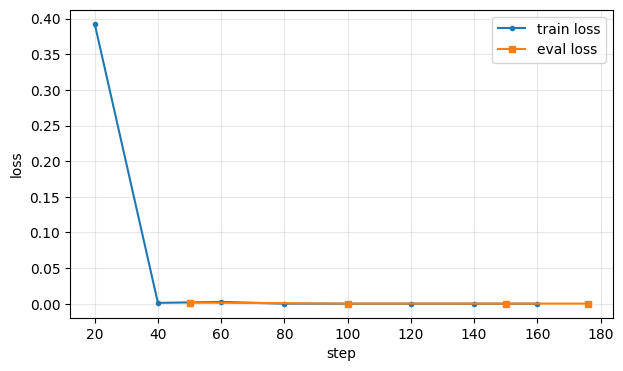

In [29]:
# 손실 곡선을 확인합니다
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

hist = trainer.state.log_history
train_loss = [(h["step"], h["loss"]) for h in hist if "loss" in h]
eval_loss = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

fig, ax = plt.subplots(figsize=(7, 4))
if train_loss:
    ax.plot(*zip(*train_loss), label="train loss", marker="o", markersize=3)
if eval_loss:
    ax.plot(*zip(*eval_loss), label="eval loss", marker="s", markersize=4)
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=0.3)
plt.savefig("loss_curve.png", dpi=100, bbox_inches="tight")
plt.close()

from IPython.display import Image as IPImage
IPImage("loss_curve.png")

**곡선에서 확인할 것**

- **학습 손실이 내려가는가** : 안 내려가면 학습률이나 데이터 형식에 문제가 있습니다  
- **검증 손실이 함께 내려가는가** : 검증 손실이 올라가기 시작하면 과적합입니다. 이론 레슨에서 말한 대로 소량 데이터에서는 금방 생깁니다

이 실습의 곡선은 학습 손실이 처음 몇십 스텝 만에 0 가까이 내려가고 검증 손실도 처음부터 0에 가깝습니다. 이론 레슨 3.6절은 손실이 0에 수렴하면 과적합이라고 했는데 여기서는 다릅니다. 데이터를 규칙으로 찍어 냈기 때문에 **입력이 출력을 완전히 정하고** 모델은 외울 것 없이 그 규칙을 그대로 배웁니다. 검증 데이터도 같은 규칙에서 나왔으니 검증 손실로는 과적합을 잡을 수 없습니다.

사내 데이터는 다릅니다. 같은 회의록을 사람 둘이 다르게 정리할 수 있어서 손실이 0까지 내려가지 않는 것이 정상이고, 0에 가까워지면 학습 데이터를 외운 것입니다. 그때는 이론 3.6절의 기준을 그대로 쓰십시오. 이 곡선에서 가져갈 것은 모양이 아니라 **학습 손실과 검증 손실을 함께 그려 놓고 읽는 습관**입니다.

In [30]:
# 어댑터를 저장합니다. 크기를 확인하세요
trainer.save_model("./qlora_adapter")
tok.save_pretrained("./qlora_adapter")      # 토크나이저도 함께 둡니다
!du -sh ./qlora_adapter
!ls ./qlora_adapter

126M	./qlora_adapter
adapter_config.json	   README.md		  training_args.bin
adapter_model.safetensors  tokenizer_config.json
chat_template.jinja	   tokenizer.json


In [31]:
# 어댑터 카드. 이론 6.4절이 "반드시 함께 적어두라"고 한 네 가지입니다.
# 안 적어두면 반년 뒤에 어느 모델에 붙는지 모르는 100MB 남짓한 파일이 됩니다
card = {
    "base_model": BASE_MODEL,
    "transformers": md.version("transformers"),
    "peft": md.version("peft"),
    "data": {"train": len(train_rows), "valid": len(valid_rows), "test": len(test_rows),
             "source": "규칙 기반 생성 (이론 4.3절 길 2)"},
    "hparams": {"r": lora_config.r, "lora_alpha": lora_config.lora_alpha,
                "target_modules": attached,          # 설정이 아니라 모델에서 읽은 값
                "epochs": sft_config.num_train_epochs,
                "learning_rate": sft_config.learning_rate, "max_length": MAX_LEN},
    "baseline": {"전_지시문없음": base_no_guide, "전_지시문있음": base_guide},
}
with open("./qlora_adapter/adapter_card.json", "w", encoding="utf-8") as f:
    json.dump(card, f, ensure_ascii=False, indent=2)
print(json.dumps(card["hparams"], ensure_ascii=False))

{"r": 16, "lora_alpha": 32, "target_modules": ["down_proj", "gate_proj", "k_proj", "o_proj", "q_proj", "up_proj", "v_proj"], "epochs": 2, "learning_rate": 0.0002, "max_length": 512}


베이스 모델은 6GB 남짓인데 학습 결과물인 어댑터는 120MB 남짓입니다. 이론 레슨에서 말한 운영상 이점으로 부서별 어댑터를 여러 개 두고 갈아 끼울 수 있습니다.

🖥 **로컬 작업** : 실습 환경의 런타임이 끊기면 이 디렉터리가 사라집니다. 사내에서는 어댑터와 카드를 사내 저장소(모델 레지스트리나 공유 스토리지)에 함께 올립니다. 카드 없이 어댑터만 올리면 반년 뒤에 못 씁니다.

## Step 6 : 전후 비교 평가

학습이 실제로 무엇을 바꿨는지 잽니다.

In [32]:
model.eval()


def gen_ft(prompt, **kw):
    """파인튜닝 '후' 모델로 생성합니다"""
    return gen(model, prompt, **kw)


print("파인튜닝 후")
ft_no_guide = evaluate(gen_ft, test_rows, use_guide=False, label="지시문 없음")
ft_guide = evaluate(gen_ft, test_rows, use_guide=True, label="지시문 있음")

파인튜닝 후
[지시문 없음] 형식 100%  담당기한 100%  결정개수 100%  날짜 100%  참석자 100%   (24.8초/건)
[지시문 있음] 형식 100%  담당기한 100%  결정개수 95%  날짜 100%  참석자 100%   (25.2초/건)


In [33]:
# gen_base 가 왜 필요한지 여기서 확인합니다.
# get_peft_model 은 base_model 을 제자리에서 고칩니다. 두 이름이 같은 모델을 가리킵니다
p = make_prompt(test_rows[0], use_guide=False)
print("gen(base_model, ...) 과 gen(model, ...) 이 같은가 :",
      gen(base_model, p, max_new_tokens=64) == gen(model, p, max_new_tokens=64))
print("gen_base(...) 와 gen(model, ...) 이 같은가       :",
      gen_base(p, max_new_tokens=64) == gen(model, p, max_new_tokens=64))

gen(base_model, ...) 과 gen(model, ...) 이 같은가 : True
gen_base(...) 와 gen(model, ...) 이 같은가       : False


`gen(base_model, ...)`과 `gen(model, ...)`의 비교가 `True`입니다. **학습이 끝난 뒤 `base_model`이라는 이름으로 불러도 어댑터가 붙은 모델이 나옵니다.**

`get_peft_model`은 새 모델을 만들어 돌려주지 않고 베이스 모델의 선형 층을 제자리에서 LoRA 층으로 갈아 끼웁니다. 그래서 "전"을 재려면 `disable_adapter()`로 어댑터를 꺼야 하고 그 일을 `gen_base`가 합니다.

이것을 모르면 **"파인튜닝 전"이라고 적힌 열에 파인튜닝 후 숫자가 들어갑니다.** 표는 멀쩡해 보이고 결론만 틀립니다.

In [34]:
# 네 조건을 한 표로 비교합니다
conds = [
    ("파인튜닝 전, 지시문 없음", base_no_guide),
    ("파인튜닝 전, 지시문 있음", base_guide),
    ("파인튜닝 후, 지시문 없음", ft_no_guide),
    ("파인튜닝 후, 지시문 있음", ft_guide),
]
keys = list(base_no_guide.keys())

print(f"{'조건':<26} " + " ".join(f"{k:>8}" for k in keys) + f" {'평균':>8}")
print("-" * (27 + 9 * (len(keys) + 1)))
for label, agg in conds:
    avg = np.mean([agg[k] for k in keys])
    print(f"{label:<26} " + " ".join(f"{agg[k]:>7.0%}" for k in keys) + f" {avg:>7.0%}")

조건                               형식     담당기한     결정개수       날짜      참석자       평균
---------------------------------------------------------------------------------
파인튜닝 전, 지시문 없음                  0%      0%      0%    100%    100%     40%
파인튜닝 전, 지시문 있음                100%     80%     70%    100%    100%     90%
파인튜닝 후, 지시문 없음                100%    100%    100%    100%    100%    100%
파인튜닝 후, 지시문 있음                100%    100%     95%    100%    100%     99%


**파인튜닝 후 지시문 없음**이 **파인튜닝 전 지시문 있음**을 따라잡았는지 보십시오. 따라잡았다면 양식 규약이 프롬프트에서 가중치로 옮겨 간 것이고 호출마다 수백 토큰을 아낍니다.

그리고 **떨어진 칸을 먼저 읽으십시오.** 올라간 칸은 보고서에 쓸 것이고 떨어진 칸이 배포 여부를 정합니다.

In [35]:
# 절감 효과를 계산합니다
saved = len(tok.encode(p_yes)) - len(tok.encode(p_no))
print(f"호출당 절감 토큰 : {saved}")
print(f"하루 1,000회 호출 시 : {saved * 1000:,} 토큰")
print(f"연간 (250 영업일) : {saved * 1000 * 250 / 1e6:.1f}M 토큰")

호출당 절감 토큰 : 223
하루 1,000회 호출 시 : 223,000 토큰
연간 (250 영업일) : 55.8M 토큰


In [36]:
# 실제 출력을 눈으로 비교합니다. 숫자로 안 잡히는 것이 여기서 보입니다
r = test_rows[0]
print("=== 원문 ===")
print(r["input"])
print("\n=== 파인튜닝 전 (지시문 없음) ===")
print(gen_base(make_prompt(r, use_guide=False))[:600])

=== 원문 ===
3월 19일 협력사 계약 관련 회의. 참석자 정하윤, 윤서아, 강도현, 최유나.
- 1번 안건 일정을 확정했다. 강도현이 4월 15일까지 진행.
- 협력사 계약 관련 2번 안건은 보류하기로 했다. 개발2팀 의견 수렴 필요.

=== 파인튜닝 전 (지시문 없음) ===
3월 19일 협력사 계약 관련 회의

참석자: 정하윤, 윤서아, 강도현, 최유나

일정:
- 1번 안건: 일정을 확정하였으며, 강도현이 4월 15일까지 진행한다.

보류:
- 2번 안건: 협력사 계약 관련 사항은 개발2팀 의견 수렴 후 보류한다.


In [37]:
print("=== 파인튜닝 후 (지시문 없음) ===")
print(gen_ft(make_prompt(r, use_guide=False))[:600])
print("\n=== 정답 ===")
print(r["output"])

=== 파인튜닝 후 (지시문 없음) ===
## 회의 개요
- 일시 : 3월 19일
- 참석 : 정하윤, 윤서아, 강도현, 최유나
- 주제 : 협력사 계약

## 결정 사항
1. 1번 안건 일정을 확정했다 / 담당: 강도현 / 기한: 4월 15일

## 논의 사항
- 협력사 계약 2번 안건: 보류하기로 했다

## 후속 조치
- 협력사 계약 2번 안건 재검토 및 의견 수렴

=== 정답 ===
## 회의 개요
- 일시 : 3월 19일
- 참석 : 정하윤, 윤서아, 강도현, 최유나
- 주제 : 협력사 계약

## 결정 사항
1. 1번 안건 일정을 확정했다 / 담당: 강도현 / 기한: 4월 15일

## 논의 사항
- 협력사 계약 2번 안건: 보류하기로 했다

## 후속 조치
- 협력사 계약 2번 안건 재검토 및 의견 수렴


## Step 7 : 망가진 것 확인

이론 레슨 5.3절의 파국적 망각입니다. 학습시킨 태스크만 보지 말고 **원래 되던 것**을 확인합니다.

In [38]:
# 실습 : 파인튜닝과 무관한 태스크로 전후를 비교하세요
# 회의록 정리와 관계없는 일반 능력이 유지되는지 봅니다
# 전후 생성은 gen_base 와 gen_ft 를 쓰십시오

general_tasks = [
    ("분류", """다음 문의를 [기술지원], [영업], [환불], [기타] 중 하나로 분류하세요. 분류 결과만 출력하세요.
문의: "결제한 구독을 취소하고 환불받고 싶습니다." """, lambda s: "[환불]" in s),
    ("추출", """다음에서 정보를 추출해 JSON으로만 출력하세요.
형식: {"회사": "", "금액": 0}
"한빛물산과 4800만원 계약을 체결했습니다." """, lambda s: "한빛물산" in s and "4800" in s.replace(",", "")),
    ("요약", """다음을 한 문장으로 요약하세요.
"당사는 3분기에 매출 144억원을 달성했으나 전분기 대비 소폭 감소했다. 원인은 계절적 수요 감소이다." """,
     lambda s: len(s.strip()) < 200 and ("감소" in s or "계절" in s)),
    ("일반대화", "파이썬에서 리스트와 튜플의 차이를 두 문장으로 설명하세요.",
     lambda s: ("변경" in s or "수정" in s or "불변" in s) and len(s) > 20),
]

# 여기에 전후 비교 코드를 작성하세요

print(f"{'태스크':<12} {'전':>6} {'후':>6}")
print("-" * 28)
before_hits, after_hits = 0, 0
for name, prompt, check in general_tasks:
    b = check(gen_base(prompt, max_new_tokens=200))
    a = check(gen_ft(prompt, max_new_tokens=200))
    before_hits += b
    after_hits += a
    print(f"{name:<12} {'O' if b else 'X':>6} {'O' if a else 'X':>6}")
print("-" * 28)
print(f"{'합계':<12} {before_hits:>4}/{len(general_tasks)} {after_hits:>4}/{len(general_tasks)}")

태스크               전      후
----------------------------
분류                X      X
추출                O      X
요약                O      X
일반대화              O      X
----------------------------
합계              3/4    0/4


<details>
<summary>정답 보기</summary>

```python
print(f"{'태스크':<12} {'전':>6} {'후':>6}")
print("-" * 28)
before_hits, after_hits = 0, 0
for name, prompt, check in general_tasks:
    b = check(gen_base(prompt, max_new_tokens=200))
    a = check(gen_ft(prompt, max_new_tokens=200))
    before_hits += b
    after_hits += a
    print(f"{name:<12} {'O' if b else 'X':>6} {'O' if a else 'X':>6}")
print("-" * 28)
print(f"{'합계':<12} {before_hits:>4}/{len(general_tasks)} {after_hits:>4}/{len(general_tasks)}")
```

이 실행에서는 **전 3/4에서 후 0/4**로 떨어졌습니다. 분류는 학습 전에도 틀렸으니 기준선의 문제이고, 추출·요약·일반대화 셋은 학습 전에 되던 것이 학습 뒤에 안 됩니다. 이론 5.3절의 파국적 망각이 그대로 나타난 것입니다.

무엇이 나왔는지 눈으로 보십시오. `print(gen_ft(general_tasks[3][1], max_new_tokens=200))`을 실행하면 리스트와 튜플의 차이를 물었을 때의 답이 찍힙니다. 학습 데이터의 형태가 강하게 각인됐다면 그 답이 회의록 양식으로 시작합니다. 학습 데이터 700건이 전부 한 형식이라 모델이 **모든 입력을 회의록으로 읽게** 된 것이고, 형식 태스크가 100%가 된 것과 같은 원인입니다.

이 결과가 Step 6의 100%를 뒤집지는 않지만 **배포 여부를 정합니다.** 이 모델을 회의록 정리 전용으로만 쓴다면 문제가 없고, 다른 일에도 쓰던 모델이었다면 그 일이 전부 멈춥니다. 대응은 이론 5.3절 그대로입니다. 학습 데이터에 일반 대화 샘플을 10퍼센트쯤 섞거나(리플레이) 에폭을 1로, alpha를 16으로 낮춰 다시 학습하고, 어느 쪽이든 이 표를 다시 찍어 확인합니다.

여기서도 `gen_base`를 썼습니다. `gen(base_model, ...)`을 쓰면 **"전" 열과 "후" 열이 같은 모델의 성적**이 되어 망각이 있어도 절대 드러나지 않습니다.

**실행 순서** : 실습 셀 끝에 정답 코드를 붙이고 그 셀을 다시 실행하십시오. `general_tasks` 정의가 같은 셀에 있어야 합니다.

</details>

## Step 8 : 선택 심화 트랙

다섯 트랙 중 **두 개를 선택**해 수행하고 공유합니다. **순서는 상관없습니다.** 어느 트랙도 다른 트랙의 결과를 쓰지 않습니다.

![표 : 트랙, 주제, 성격, 난이도](https://resources-public-prd.modulabs.co.kr/home-section/main-banner/88ea59e7-48f1-485d-9d85-1663e1aab8c6.jpg)

In [ ]:
# 트랙 공통 1 : 앞 단계가 끝났는지 먼저 확인합니다
need = ["base_model", "model", "tok", "train_rows", "test_rows", "MAX_LEN",
        "bnb", "to_chat", "evaluate", "gen_base", "gen_ft"]
missing = [n for n in need if n not in globals()]
if missing:
    print("Step 0~6 을 먼저 실행하십시오. 없는 것 :", missing)
else:
    print("준비됐습니다. 아무 트랙이나 먼저 하셔도 됩니다.")

준비됐습니다. 아무 트랙이나 먼저 하셔도 됩니다.

In [ ]:
# 트랙 공통 2 : 한 가지 설정으로 학습하고 재는 함수. 트랙 1, 2, 3 이 함께 씁니다
def train_variant(r, lora_alpha, targets, tag, rows=None, n_train=300,
                  epochs=1, n_eval=15):
    """설정 하나를 학습하고 학습 파라미터 수, 시간, 점수를 돌려줍니다"""
    rows = rows if rows is not None else train_rows[:n_train]

    m = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=bnb,
                                             device_map="auto", dtype=COMPUTE_DTYPE)
    m = prepare_model_for_kbit_training(m)
    m = get_peft_model(m, LoraConfig(r=r, lora_alpha=lora_alpha, lora_dropout=0.05,
                                     target_modules=targets, bias="none",
                                     task_type="CAUSAL_LM"))
    n_trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)

    args = SFTConfig(output_dir=f"./var_{tag}", num_train_epochs=epochs,
                     per_device_train_batch_size=1, gradient_accumulation_steps=8,
                     learning_rate=2e-4, logging_steps=50,
                     bf16=USE_BF16, fp16=not USE_BF16,
                     gradient_checkpointing=True, max_length=MAX_LEN,
                     assistant_only_loss=True, report_to="none",
                     save_strategy="no", seed=42)
    tr = SFTTrainer(model=m, args=args, train_dataset=Dataset.from_list(to_chat(rows)),
                    processing_class=tok)
    if not USE_BF16:                                   # Step 5 와 같은 이유. fp16 GPU 에서는 어댑터를 fp32 로
        for p in m.parameters():
            if p.requires_grad:
                p.data = p.data.float()
    t0 = time.time()
    tr.train()
    minutes = (time.time() - t0) / 60

    m.config.use_cache = True
    m.eval()
    agg = evaluate(lambda prompt: gen(m, prompt), test_rows,
                   use_guide=False, label=tag, n=n_eval)

    # 학습 한 번이 남기는 옵티마이저 상태와 기울기 버퍼까지 돌려줍니다. 안 하면 설정마다 1GB 안팎이 쌓여
    # 뒤에 돌리는 트랙에서 VRAM 이 모자랍니다
    tr.accelerator.free_memory()
    del tr.optimizer, tr.lr_scheduler
    del m, tr
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    print(f"  [정리 후 VRAM] {vram_gb():.2f} GB")
    return {"tag": tag, "r": r, "alpha": lora_alpha, "params": n_trainable,
            "minutes": minutes, "agg": agg, "score": float(np.mean(list(agg.values())))}


ATTN = ["q_proj", "k_proj", "v_proj", "o_proj"]
print("train_variant 준비 완료")

train_variant 준비 완료

#### 트랙 1 : LoRA 하이퍼파라미터 비교

이론 레슨 3.2절에서 `target_modules`가, 3.3절에서 r이 영향이 크다고 했습니다. 3.4절에서 **흔한 실수**로 든 r을 올리면서 alpha를 그대로 두는 경우도 직접 겪어 봅니다.

In [ ]:
# 실습 : 네 가지 설정으로 학습해 성능과 학습 파라미터 수, 학습 시간을 비교하세요
#  A : r=8,  alpha=16, 어텐션만 (ATTN)
#  B : r=16, alpha=32, 모든 선형 층  (기준선)
#  C : r=32, alpha=64, 모든 선형 층  (r 을 올리고 alpha 도 같이 올림)
#  D : r=32, alpha=32, 모든 선형 층  (r 만 올리고 alpha 는 그대로)
#
# C 와 D 는 r 이 같습니다. 다른 것은 alpha 나누기 r 뿐입니다.
# 학습 시간을 줄이려면 n_train=300, epochs=1 로 두십시오

variants = [
    train_variant(8,  16, ATTN,         "A_r8_a16_attn"),
    train_variant(16, 32, "all-linear", "B_r16_a32_all"),
    train_variant(32, 64, "all-linear", "C_r32_a64_all"),
    train_variant(32, 32, "all-linear", "D_r32_a32_all"),
]

print(f"\n{'설정':<15} {'r':>4} {'alpha':>6} {'alpha/r':>8} "
      f"{'학습 파라미터':>14} {'시간(분)':>9} {'평균 점수':>10}")
print("-" * 72)
for v in variants:
    print(f"{v['tag']:<15} {v['r']:>4} {v['alpha']:>6} {v['alpha']/v['r']:>8.1f} "
          f"{v['params']:>14,} {v['minutes']:>9.1f} {v['score']:>9.0%}")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

...

Tokenizing train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

{'train_runtime': '312.9', 'train_samples_per_second': '0.959', 'train_steps_per_second': '0.121', 'train_loss': '0.09418', 'entropy': '0.09995', 'mean_token_accuracy': '0.9781', 'num_tokens': '1.114e+05', 'epoch': '1'}
[D_r32_a32_all] 형식 100%  담당기한 100%  결정개수 100%  날짜 100%  참석자 100%   (24.5초/건)
  [정리 후 VRAM] 3.07 GB

설정                 r  alpha  alpha/r        학습 파라미터     시간(분)      평균 점수
------------------------------------------------------------------------
A_r8_a16_attn      8     16      2.0      3,686,400       4.2       95%
B_r16_a32_all     16     32      2.0     29,933,568       5.2      100%
C_r32_a64_all     32     64      2.0     59,867,136       5.2      100%
D_r32_a32_all     32     32      1.0     59,867,136       5.2      100%

<details>
<summary>정답 보기</summary>

```python
variants = [
    train_variant(8,  16, ATTN,         "A_r8_a16_attn"),
    train_variant(16, 32, "all-linear", "B_r16_a32_all"),
    train_variant(32, 64, "all-linear", "C_r32_a64_all"),
    train_variant(32, 32, "all-linear", "D_r32_a32_all"),
]

print(f"\n{'설정':<15} {'r':>4} {'alpha':>6} {'alpha/r':>8} "
      f"{'학습 파라미터':>14} {'시간(분)':>9} {'평균 점수':>10}")
print("-" * 72)
for v in variants:
    print(f"{v['tag']:<15} {v['r']:>4} {v['alpha']:>6} {v['alpha']/v['r']:>8.1f} "
          f"{v['params']:>14,} {v['minutes']:>9.1f} {v['score']:>9.0%}")
```

이 실행의 표는 A 95%, B·C·D 100%입니다. 이 순서로 읽습니다.

**A와 B를 비교합니다.** 어텐션에만 붙인 A는 담당기한과 결정개수에서 87%에 그쳤고 모든 선형 층에 붙인 B는 전부 100%입니다. 학습 파라미터는 8배 늘었지만 시간은 1분 차이입니다. 이론 3.2절의 결론 그대로입니다.

**B·C·D는 점수가 같습니다.** 이 태스크는 r=16으로 이미 상한이라 점수로는 r과 alpha의 차이가 보이지 않습니다. 이럴 때는 표 위에 찍힌 학습 로그의 `train_loss`를 봅니다. B 0.093, C 0.066, D 0.094입니다.

**B와 C를 비교합니다.** r을 16에서 32로 올리면서 alpha도 32에서 64로 함께 올려 비율 2를 유지했더니 손실이 0.093에서 0.066으로 내려갔습니다. 용량이 늘어 더 배운 것입니다.

**C와 D를 비교합니다. 여기가 오늘의 함정입니다.** 둘 다 r이 32인데 D만 alpha를 32로 두었습니다. alpha 나누기 r이 2에서 1로 줄었으므로 **용량은 같은데 세기가 절반**이고, 손실은 0.094로 r이 16인 B와 같은 자리로 돌아갔습니다. r을 두 배로 올린 효과가 alpha를 안 올리자 사라진 것입니다. D만 돌려 보고 B와 비교했다면 "r을 32로 올려도 소용없다"는 틀린 결론을 내렸을 것입니다. 이론 3.4절이 말한 실수입니다.

**가져갈 습관** : 비교 실험을 할 때 **바꾼 값 하나 때문에 따라 움직여야 하는 값이 있는지** 먼저 확인하십시오. LoRA에서는 r과 alpha가 그 관계입니다.

**실행 순서** : 실습 셀의 `variants = []`를 정답 코드로 바꾸고 실습 셀부터 다시 실행하십시오. `train_variant` 셀이 먼저 실행되어 있어야 합니다.

</details>

#### 트랙 2 : 데이터 규모와 성능 곡선

이론 레슨 4.1절에서 형식과 어투는 적은 데이터에서 빠르게 오르다 정체한다고 했습니다. 우리 태스크에서 몇 건이 필요한지 잽니다.

In [ ]:
# 실습 : 학습 데이터를 100, 300, 700건으로 바꿔 학습하고 성능 곡선을 그리세요
# 다른 조건은 고정합니다 (epochs=1, r=16, alpha=32, all-linear)

curve = []
for n in [100, 300, 700]:
    res = train_variant(16, 32, "all-linear", f"n{n}", n_train=n, epochs=1)
    curve.append((n, res["score"]))

print(f"\n{'데이터 건수':>12} {'평균 점수':>10} {'직전 대비':>10}")
print("-" * 36)
prev = None
for n, s in curve:
    delta = "-" if prev is None else f"{(s - prev) * 100:+.0f}%p"
    print(f"{n:>12} {s:>9.0%} {delta:>10}")
    prev = s

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

...

Tokenizing train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/700 [00:00<?, ? examples/s]

{'loss': '0.07131', 'grad_norm': '0.001108', 'learning_rate': '8.864e-05', 'entropy': '0.07011', 'mean_token_accuracy': '0.984', 'num_tokens': '1.473e+05', 'epoch': '0.5714'}
{'train_runtime': '727.8', 'train_samples_per_second': '0.962', 'train_steps_per_second': '0.121', 'train_loss': '0.04056', 'entropy': '0.0009292', 'mean_token_accuracy': '1', 'num_tokens': '2.602e+05', 'epoch': '1'}
[n700] 형식 100%  담당기한 100%  결정개수 100%  날짜 100%  참석자 100%   (24.4초/건)
  [정리 후 VRAM] 3.07 GB

      데이터 건수      평균 점수      직전 대비
------------------------------------
         100       87%          -
         300      100%      +13%p
         700      100%       +0%p

<details>
<summary>정답 보기</summary>

```python
curve = []
for n in [100, 300, 700]:
    res = train_variant(16, 32, "all-linear", f"n{n}", n_train=n, epochs=1)
    curve.append((n, res["score"]))

print(f"\n{'데이터 건수':>12} {'평균 점수':>10} {'직전 대비':>10}")
print("-" * 36)
prev = None
for n, s in curve:
    delta = "-" if prev is None else f"{(s - prev) * 100:+.0f}%p"
    print(f"{n:>12} {s:>9.0%} {delta:>10}")
    prev = s
```

**직전 대비 열을 보십시오.** 형식 학습은 데이터가 적어도 빠르게 수렴해서 100건에서 이미 상당히 오르고 300건과 700건의 차이가 작을 수 있습니다.

그러니 데이터를 수천 건 모으느라 몇 주를 쓰는 대신 **100건을 잘 만들어 먼저 검증하는 편**이 합리적입니다. 곡선이 정체되는 지점을 찾으면 그 이상 모을 필요가 없습니다.

다만 태스크에 따라 다릅니다. 형식 학습은 적게 필요하고 도메인 지식이나 복잡한 추론은 훨씬 많이 필요합니다.

**실행 순서** : 실습 셀의 `curve = []`를 정답 코드로 바꾸고 실습 셀부터 다시 실행하십시오.

</details>

#### 트랙 3 : 데이터 오염 주입 실험

엉성한 데이터를 학습하면 엉성한 것을 배우는지 직접 확인합니다.

In [ ]:
# 실습 : 학습 데이터의 일부를 의도적으로 오염시키고 학습해 성능 변화를 측정하세요
# 오염 방식 세 가지
#  drop_owner    : 담당자와 기한을 뺀 출력
#  drop_section  : 섹션 헤더가 빠진 출력
#  hallucinate   : 원문에 없는 내용이 추가된 출력
# 오염 비율 0%, 10%, 30% 로 비교하세요

def corrupt(row, mode=None):
    r = dict(row)
    out = r["output"]
    mode = mode or random.choice(["drop_owner", "drop_section", "hallucinate"])

    if mode == "drop_owner":
        out = re.sub(r" / 담당: [^/]+ / 기한: .+", "", out)
    elif mode == "drop_section":
        out = out.split("## 논의 사항")[0].strip()
    else:
        out = out + "\n- 추가 예산 4800만원 집행 승인됨"     # 원문에 없는 내용

    r["output"] = out
    return r

def make_corrupted(rows, ratio):
    rows = [dict(x) for x in rows]
    rnd = random.Random(42)                                 # 비율마다 같은 자리를 오염시킵니다
    for i in rnd.sample(range(len(rows)), int(len(rows) * ratio)):
        rows[i] = corrupt(rows[i])
    return rows

# 먼저 Step 3 의 센서로 오염이 실제로 들어갔는지 확인합니다
for ratio in [0.0, 0.1, 0.3]:
    data = make_corrupted(train_rows[:300], ratio)
    rep = validate_dataset(data)
    print(f"오염 {ratio:.0%} : 형식 {len(rep['format_fail'])}건, "
          f"규칙 {len(rep['rule_fail'])}건, 사실 {len(rep['fact_fail'])}건")

# 그다음 학습합니다
results = []
for ratio in [0.0, 0.1, 0.3]:
    data = make_corrupted(train_rows[:300], ratio)
    res = train_variant(16, 32, "all-linear", f"corrupt{int(ratio*100)}", rows=data)
    results.append((ratio, res))

keys = list(results[0][1]["agg"].keys())
print(f"\n{'오염 비율':>8} " + " ".join(f"{k:>8}" for k in keys) + f" {'평균':>8}")
print("-" * (9 + 9 * (len(keys) + 1)))
for ratio, res in results:
    print(f"{ratio:>7.0%} " + " ".join(f"{res['agg'][k]:>7.0%}" for k in keys)
          + f" {res['score']:>7.0%}")

오염 0% : 형식 0건, 규칙 0건, 사실 0건
오염 10% : 형식 2건, 규칙 16건, 사실 14건
오염 30% : 형식 32건, 규칙 63건, 사실 27건

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

...

Tokenizing train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

{'train_runtime': '307.3', 'train_samples_per_second': '0.976', 'train_steps_per_second': '0.124', 'train_loss': '0.1123', 'entropy': '0.1127', 'mean_token_accuracy': '0.9735', 'num_tokens': '1.091e+05', 'epoch': '1'}
[corrupt30] 형식 100%  담당기한 100%  결정개수 100%  날짜 100%  참석자 100%   (23.6초/건)
  [정리 후 VRAM] 3.07 GB

   오염 비율       형식     담당기한     결정개수       날짜      참석자       평균
---------------------------------------------------------------
     0%    100%    100%    100%    100%    100%    100%
    10%    100%    100%    100%    100%    100%    100%
    30%    100%    100%    100%    100%    100%    100%

<details>
<summary>정답 보기</summary>

```python
def corrupt(row, mode=None):
    r = dict(row)
    out = r["output"]
    mode = mode or random.choice(["drop_owner", "drop_section", "hallucinate"])

    if mode == "drop_owner":
        out = re.sub(r" / 담당: [^/]+ / 기한: .+", "", out)
    elif mode == "drop_section":
        out = out.split("## 논의 사항")[0].strip()
    else:
        out = out + "\n- 추가 예산 4800만원 집행 승인됨"     # 원문에 없는 내용

    r["output"] = out
    return r

def make_corrupted(rows, ratio):
    rows = [dict(x) for x in rows]
    rnd = random.Random(42)                                 # 비율마다 같은 자리를 오염시킵니다
    for i in rnd.sample(range(len(rows)), int(len(rows) * ratio)):
        rows[i] = corrupt(rows[i])
    return rows

# 먼저 Step 3 의 센서로 오염이 실제로 들어갔는지 확인합니다
for ratio in [0.0, 0.1, 0.3]:
    data = make_corrupted(train_rows[:300], ratio)
    rep = validate_dataset(data)
    print(f"오염 {ratio:.0%} : 형식 {len(rep['format_fail'])}건, "
          f"규칙 {len(rep['rule_fail'])}건, 사실 {len(rep['fact_fail'])}건")

# 그다음 학습합니다
results = []
for ratio in [0.0, 0.1, 0.3]:
    data = make_corrupted(train_rows[:300], ratio)
    res = train_variant(16, 32, "all-linear", f"corrupt{int(ratio*100)}", rows=data)
    results.append((ratio, res))

keys = list(results[0][1]["agg"].keys())
print(f"\n{'오염 비율':>8} " + " ".join(f"{k:>8}" for k in keys) + f" {'평균':>8}")
print("-" * (9 + 9 * (len(keys) + 1)))
for ratio, res in results:
    print(f"{ratio:>7.0%} " + " ".join(f"{res['agg'][k]:>7.0%}" for k in keys)
          + f" {res['score']:>7.0%}")
```

학습 전에 **센서를 먼저 돌렸습니다.** 오염을 넣었다고 생각했는데 실제로는 안 들어간 채로 학습하면 차이가 없는 결과를 보고 "데이터 품질은 별 영향이 없다"는 정반대 결론을 냅니다.

이 실행에서는 오염 0·10·30% 모두 100%입니다. 센서 표를 먼저 보십시오. 30%에서 형식 32건·규칙 63건·사실 27건이 걸렸으니 오염은 분명히 들어갔습니다. 들어갔는데도 점수가 안 떨어진 이유가 이 트랙의 결론입니다.

첫째, 세 종류를 무작위로 섞어서 한 종류당 오염은 3~10%에 그치고 정상 데이터가 다수라 모델이 다수의 형태를 따릅니다. 둘째, 이 태스크는 규칙으로 찍어 낸 데이터라 정답이 하나뿐이어서 다수 쪽이 강하게 각인됩니다. 다만 학습 로그의 `train_loss`는 0.093, 0.108, 0.112로 오염에 따라 올라갑니다. 점수에는 안 보여도 모델은 흔들렸습니다.

실무에서는 오염이 무작위가 아니라 **특정 패턴으로 쏠립니다.** 상담원 한 사람이 담당자를 늘 빼먹는 식입니다. 이 코드로 직접 확인해 보십시오. `corrupt(row, mode="drop_owner")`처럼 한 종류만 넣어 30%와 50%로 학습하면 `담당기한` 열이 먼저 떨어지는지 보입니다. **오염의 종류가 결과의 종류를 결정하므로** 점수 하나가 아니라 항목별로 봐야 원인을 짚습니다.

**실행 순서** : 실습 셀의 `corrupt`와 `make_corrupted`를 정답 코드로 채우고 실습 셀부터 다시 실행한 뒤 나머지 코드를 이어서 실행하십시오.

</details>

#### 트랙 4 : 어댑터 병합과 추론 속도

이론 레슨 6.4절에서 다룬 병합의 득실을 실제로 잽니다.

In [40]:
# 실습 : 어댑터를 베이스에 병합하고, 병합 전후 추론 속도를 비교하세요
# 주의 1 : 4bit 모델에 바로 병합하면 반올림 오차가 생기므로(PEFT 가 경고) fp16 으로 다시 로드해 병합합니다
# 주의 2 : base_model 과 model 을 지우지 마십시오.
#          Step 7 과 트랙 5 가 그 두 이름을 계속 씁니다

from peft import PeftModel

def measure_speed(m, n=5):
    """초당 생성 토큰 수"""
    total_tok, t0 = 0, time.time()
    for r in test_rows[:n]:
        msgs = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": make_prompt(r, use_guide=False)}]
        text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        ids = tok(text, return_tensors="pt").to(m.device)
        with torch.no_grad():
            out = m.generate(**ids, max_new_tokens=300, do_sample=False,
                             pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        total_tok += out.shape[1] - ids["input_ids"].shape[1]
    return total_tok / (time.time() - t0)

tps_adapter = measure_speed(model)
print(f"4bit + 어댑터 : {tps_adapter:.1f} tok/s")

# fp16 베이스를 '따로' 올립니다. 4bit 베이스는 그대로 둡니다
need_gb = N_PARAMS * 2 / 1e9 + 1.0          # fp16 은 파라미터당 2바이트, 여유 1GB
free_gb = (torch.cuda.get_device_properties(0).total_memory / 1e9 - vram_gb()) if HAS_GPU else 0.0

if HAS_GPU and free_gb < need_gb:
    print(f"VRAM 이 모자랍니다 (필요 {need_gb:.1f}GB, 남은 {free_gb:.1f}GB).")
    print("런타임을 재시작하고 Step 0~5 를 다시 실행한 뒤 이 트랙만 도십시오.")
else:
    fp16_base = peft_fp16 = merged = None
    try:
        fp16_base = AutoModelForCausalLM.from_pretrained(      # dtype= 입니다. torch_dtype= 이 아닙니다
            BASE_MODEL, dtype=COMPUTE_DTYPE, device_map="auto")
        peft_fp16 = PeftModel.from_pretrained(fp16_base, "./qlora_adapter").eval()
        tps_fp16_adapter = measure_speed(peft_fp16)          # 같은 fp16 베이스에 어댑터만 얹은 상태
        print(f"fp16 + 어댑터 : {tps_fp16_adapter:.1f} tok/s")

        merged = peft_fp16.merge_and_unload()
        merged.eval()
        tps_merged = measure_speed(merged)
        print(f"fp16 병합     : {tps_merged:.1f} tok/s")
        print(f"VRAM : {vram_gb():.2f} GB (4bit 베이스 + fp16 베이스가 함께 올라가 있습니다)")
        merged.save_pretrained("./merged_model")
    finally:
        # 도중에 오류가 나도 fp16 모델을 반드시 내립니다. 남겨 두면 오류 기록이 붙잡아 VRAM 이 돌아오지 않습니다.
        # base_model 과 model 은 건드리지 않습니다
        del merged, peft_fp16, fp16_base
        gc.collect()
        if HAS_GPU:
            torch.cuda.empty_cache()
        print(f"정리 후 VRAM : {vram_gb():.2f} GB")

4bit + 어댑터 : 7.6 tok/s


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

fp16 + 어댑터 : 10.0 tok/s
fp16 병합     : 19.5 tok/s
VRAM : 9.24 GB (4bit 베이스 + fp16 베이스가 함께 올라가 있습니다)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

정리 후 VRAM : 3.07 GB


<details>
<summary>정답 보기</summary>

```python
from peft import PeftModel

def measure_speed(m, n=5):
    """초당 생성 토큰 수"""
    total_tok, t0 = 0, time.time()
    for r in test_rows[:n]:
        msgs = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": make_prompt(r, use_guide=False)}]
        text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        ids = tok(text, return_tensors="pt").to(m.device)
        with torch.no_grad():
            out = m.generate(**ids, max_new_tokens=300, do_sample=False,
                             pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        total_tok += out.shape[1] - ids["input_ids"].shape[1]
    return total_tok / (time.time() - t0)

tps_adapter = measure_speed(model)
print(f"4bit + 어댑터 : {tps_adapter:.1f} tok/s")

# fp16 베이스를 '따로' 올립니다. 4bit 베이스는 그대로 둡니다
need_gb = N_PARAMS * 2 / 1e9 + 1.0          # fp16 은 파라미터당 2바이트, 여유 1GB
free_gb = (torch.cuda.get_device_properties(0).total_memory / 1e9 - vram_gb()) if HAS_GPU else 0.0

if HAS_GPU and free_gb < need_gb:
    print(f"VRAM 이 모자랍니다 (필요 {need_gb:.1f}GB, 남은 {free_gb:.1f}GB).")
    print("런타임을 재시작하고 Step 0~5 를 다시 실행한 뒤 이 트랙만 도십시오.")
else:
    fp16_base = peft_fp16 = merged = None
    try:
        fp16_base = AutoModelForCausalLM.from_pretrained(      # dtype= 입니다. torch_dtype= 이 아닙니다
            BASE_MODEL, dtype=COMPUTE_DTYPE, device_map="auto")
        peft_fp16 = PeftModel.from_pretrained(fp16_base, "./qlora_adapter").eval()
        tps_fp16_adapter = measure_speed(peft_fp16)          # 같은 fp16 베이스에 어댑터만 얹은 상태
        print(f"fp16 + 어댑터 : {tps_fp16_adapter:.1f} tok/s")

        merged = peft_fp16.merge_and_unload()
        merged.eval()
        tps_merged = measure_speed(merged)
        print(f"fp16 병합     : {tps_merged:.1f} tok/s")
        print(f"VRAM : {vram_gb():.2f} GB (4bit 베이스 + fp16 베이스가 함께 올라가 있습니다)")
        merged.save_pretrained("./merged_model")
    finally:
        # 도중에 오류가 나도 fp16 모델을 반드시 내립니다. 남겨 두면 오류 기록이 붙잡아 VRAM 이 돌아오지 않습니다.
        # base_model 과 model 은 건드리지 않습니다
        del merged, peft_fp16, fp16_base
        gc.collect()
        if HAS_GPU:
            torch.cuda.empty_cache()
        print(f"정리 후 VRAM : {vram_gb():.2f} GB")
```

세 숫자를 나란히 읽으십시오. 이 실행에서는 **4bit + 어댑터 7.6, fp16 + 어댑터 9.9, fp16 병합 19.6 tok/s**였습니다. 첫째와 둘째의 차이가 정밀도(4bit 가중치를 매번 푸는 비용)이고 둘째와 셋째의 차이가 병합의 효과입니다.

병합 효과가 정밀도 효과보다 컸습니다. 어댑터가 붙은 모델은 선형 층 하나를 지날 때마다 작은 행렬곱 두 번과 자료형 변환이 더 붙는데, 층 일곱 개 × 블록 서른여섯 개면 호출마다 250번이 넘고 한 건씩 생성하는 지금 조건에서는 이 비용이 가중치 계산과 맞먹습니다. 병합은 그 경로를 통째로 없앱니다. 사용자가 많아 배치가 커지면 이 비율은 줄어듭니다.

다만 fp16으로 올렸으니 VRAM이 9.2GB까지 늘었습니다. 3B라 우리 GPU에 올라가지만 7B는 어렵습니다.

`try/finally`로 감싼 이유가 있습니다. fp16 모델을 올린 뒤 어디선가 오류가 나면 그 셀의 변수가 오류 기록에 붙잡혀 6GB가 돌아오지 않고, 그 상태에서는 이 트랙을 다시 돌릴 수 없습니다. `finally`는 성공하든 실패하든 내리는 코드를 꼭 실행합니다.

Step 7과 트랙 5가 두 이름을 계속 쓰므로 **`del base_model, model`은 하지 않았습니다.** 여기서 지우면 트랙을 어떤 순서로 하느냐에 따라 Step 7이나 트랙 5의 셀이 `NameError`로 멈춥니다. **어느 트랙도 다른 트랙의 뒷정리에 기대면 안 됩니다.**

**어댑터를 여러 개 갈아 끼워야 하면 병합하지 않습니다. 하나로 고정해 운영한다면 병합합니다.** 병합한 뒤 다시 양자화해 서빙하는 것이 일반적인 배포 형태이고 그 과정은 서빙 심화 주간에서 다룹니다.

**실행 순서** : 정답 코드를 실습 셀에 붙여 실행하십시오. Step 5의 어댑터 저장 셀이 먼저 실행되어 있어야 합니다.

</details>

#### 트랙 5 : 파인튜닝 vs 하네스 정면 비교

컨텍스트와 하네스 노드의 하네스와 오늘의 파인튜닝을 같은 태스크에서 비교합니다. 실무에서 가장 자주 내려야 하는 판단입니다.

In [39]:
# 실습 : 세 조건을 비교하세요
#  A : 베이스 + 긴 지시문 (프롬프트만)
#  B : 베이스 + 지시문 + 센서 + 재시도 루프 (하네스)
#  C : 파인튜닝 모델 + 짧은 지시문
# 비교 지표 : 성적, 평균 호출 횟수, 평균 토큰, 평균 소요 시간
# 주의 : '베이스' 는 gen_base 로 부릅니다. gen(base_model, ...) 은 어댑터가 켜진 모델입니다

def run_with_harness(row, max_retry=3):
    """베이스 모델 + 센서 + 재시도. 어댑터는 꺼둡니다"""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": make_prompt(row, use_guide=True)}]
    calls, tokens, ans = 0, 0, ""

    for attempt in range(max_retry):
        text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        tokens += len(tok.encode(text))
        ids = tok(text, return_tensors="pt").to(base_model.device)

        kw = {"max_new_tokens": 512, "do_sample": attempt > 0,
              "pad_token_id": tok.pad_token_id, "eos_token_id": tok.eos_token_id}
        if attempt > 0:
            kw["temperature"] = 0.3            # 샘플링일 때만 넘깁니다

        with model.disable_adapter():          # 어댑터를 끈 '전' 모델
            with torch.no_grad():
                out = base_model.generate(**ids, **kw)
        ans = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)
        calls += 1

        checks = score_output(ans, row["meta"])
        if all(checks.values()):
            return ans, True, calls, tokens

        fails = [k for k, v in checks.items() if not v]
        msgs.append({"role": "assistant", "content": ans})
        msgs.append({"role": "user",
                     "content": f"다음 항목이 누락되었습니다: {', '.join(fails)}. "
                                "표준 양식을 다시 확인해 수정본을 작성하세요."})
    return ans, False, calls, tokens

def bench(label, fn, n=15):
    hits, calls, tokens, t0 = 0, 0, 0, time.time()
    for r in test_rows[:n]:
        ok, c, tk_ = fn(r)
        hits += ok
        calls += c
        tokens += tk_
    elapsed = time.time() - t0
    print(f"{label:<28} 성공 {hits/n:>4.0%}  호출 {calls/n:>4.1f}회  "
          f"토큰 {tokens//n:>6}  {elapsed/n:>5.1f}초")

# 조건 A : 프롬프트만
def cond_a(r):
    p = make_prompt(r, use_guide=True)
    ans = gen_base(p)
    return all(score_output(ans, r["meta"]).values()), 1, len(tok.encode(p))

# 조건 B : 하네스
def cond_b(r):
    _, ok, calls, tokens = run_with_harness(r)
    return ok, calls, tokens

# 조건 C : 파인튜닝
def cond_c(r):
    p = make_prompt(r, use_guide=False)
    ans = gen_ft(p)
    return all(score_output(ans, r["meta"]).values()), 1, len(tok.encode(p))

bench("A. 프롬프트만", cond_a)
bench("B. 하네스 (재시도)", cond_b)
bench("C. 파인튜닝", cond_c)

A. 프롬프트만                     성공  60%  호출  1.0회  토큰    375   17.4초
B. 하네스 (재시도)                 성공  60%  호출  1.8회  토큰   1122   38.8초
C. 파인튜닝                      성공 100%  호출  1.0회  토큰    152   23.8초


<details>
<summary>정답 보기</summary>

```python
def run_with_harness(row, max_retry=3):
    """베이스 모델 + 센서 + 재시도. 어댑터는 꺼둡니다"""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": make_prompt(row, use_guide=True)}]
    calls, tokens, ans = 0, 0, ""

    for attempt in range(max_retry):
        text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        tokens += len(tok.encode(text))
        ids = tok(text, return_tensors="pt").to(base_model.device)

        kw = {"max_new_tokens": 512, "do_sample": attempt > 0,
              "pad_token_id": tok.pad_token_id, "eos_token_id": tok.eos_token_id}
        if attempt > 0:
            kw["temperature"] = 0.3            # 샘플링일 때만 넘깁니다

        with model.disable_adapter():          # 어댑터를 끈 '전' 모델
            with torch.no_grad():
                out = base_model.generate(**ids, **kw)
        ans = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)
        calls += 1

        checks = score_output(ans, row["meta"])
        if all(checks.values()):
            return ans, True, calls, tokens

        fails = [k for k, v in checks.items() if not v]
        msgs.append({"role": "assistant", "content": ans})
        msgs.append({"role": "user",
                     "content": f"다음 항목이 누락되었습니다: {', '.join(fails)}. "
                                "표준 양식을 다시 확인해 수정본을 작성하세요."})
    return ans, False, calls, tokens

def bench(label, fn, n=15):
    hits, calls, tokens, t0 = 0, 0, 0, time.time()
    for r in test_rows[:n]:
        ok, c, tk_ = fn(r)
        hits += ok
        calls += c
        tokens += tk_
    elapsed = time.time() - t0
    print(f"{label:<28} 성공 {hits/n:>4.0%}  호출 {calls/n:>4.1f}회  "
          f"토큰 {tokens//n:>6}  {elapsed/n:>5.1f}초")

# 조건 A : 프롬프트만
def cond_a(r):
    p = make_prompt(r, use_guide=True)
    ans = gen_base(p)
    return all(score_output(ans, r["meta"]).values()), 1, len(tok.encode(p))

# 조건 B : 하네스
def cond_b(r):
    _, ok, calls, tokens = run_with_harness(r)
    return ok, calls, tokens

# 조건 C : 파인튜닝
def cond_c(r):
    p = make_prompt(r, use_guide=False)
    ans = gen_ft(p)
    return all(score_output(ans, r["meta"]).values()), 1, len(tok.encode(p))

bench("A. 프롬프트만", cond_a)
bench("B. 하네스 (재시도)", cond_b)
bench("C. 파인튜닝", cond_c)
```

이 실행의 표입니다. **A 프롬프트만 60%(호출 1.0회, 375토큰, 17.2초), B 하네스 60%(1.8회, 1,116토큰, 38.7초), C 파인튜닝 100%(1.0회, 152토큰, 23.5초).**

**하네스는 성적을 올리지 못했고 비용만 늘었습니다.** 재시도가 호출을 1.8배, 토큰을 3배로 늘렸는데 성공률은 60% 그대로입니다. 틀린 건이 결정개수와 담당기한, 곧 어느 안건이 결정됐는지를 가리는 판단이었기 때문입니다. "다음 항목이 누락되었습니다"라는 피드백은 무엇이 틀렸는지만 말하고 어떻게 고칠지는 말하지 못해 모델이 같은 판단을 되풀이합니다. 형식 문제였다면 하네스가 고쳤을 것입니다.

**파인튜닝은 한 번에 성공하고 토큰은 A의 40%, B의 14%입니다.** 다만 학습에 든 25분과 데이터 제작 비용은 이 표에 나타나지 않습니다. 호출당 시간이 A보다 긴 것은 양식을 끝까지 다 쓰기 때문입니다.

그래서 판단 기준은 **호출 빈도**입니다. 하루 열 번 쓰는 기능이면 학습 비용을 회수할 수 없으니 하네스가 낫고 하루 수천 번 쓰는 기능이면 파인튜닝이 훨씬 유리합니다.

둘은 배타적이지 않습니다. 파인튜닝한 모델에 센서를 붙이면 성적이 더 오르고 실무의 최종 형태는 보통 이 조합입니다.

**실행 순서** : 정답 코드를 실습 셀에 붙여 실행하십시오. 조건 A와 B가 `gen_base`와 `disable_adapter()`를 쓰는지 확인하십시오. 여기서 `base_model`을 그냥 부르면 세 조건이 전부 파인튜닝 모델이 됩니다.

</details>

## Step 9 : 공유와 정리

각자 수행한 두 트랙을 공유합니다.

**1. 선택한 트랙과 측정 결과**

**2. 파인튜닝 전후 비교표** : 네 조건의 성적과 토큰 절감량

**3. 망가진 것** : 일반 능력 평가에서 떨어진 항목과 그 원인 추정

**4. 이 태스크에 대한 최종 권고** : 파인튜닝을 쓸지, 하네스로 갈지, 둘을 조합할지. 근거는 호출 빈도와 학습 비용

처음으로 모델 가중치를 바꿨고 **파인튜닝은 새로운 능력을 준 것이 아니라 프롬프트로 하던 일을 가중치로 옮긴 것**임을 확인했습니다. 성적은 지시문을 넣었을 때와 비슷해지고 대신 토큰이 절약됩니다.

대가도 확인했습니다. 학습 시간, 데이터 제작 비용, 그리고 원래 되던 것이 약해질 위험입니다.

측정 장치도 세 개 만들었습니다. 데이터에 대는 자(`validate_dataset`), 출력에 대는 자(`score_output`), 그리고 그 자가 진짜로 작동하는지 확인하는 자(센서 자체 검사)입니다. 센서 자체 검사가 없으면 두 자를 믿을 근거가 없습니다.

이제 앞선 노드들을 거치며 LLM을 다루는 모든 층위를 만났습니다.

![표 : 층위, 우리가 배운 것](https://resources-public-prd.modulabs.co.kr/home-section/main-banner/ce436472-4c45-4de0-beaa-079b998869a7.jpg)

이 다음에는 이것들을 **운영 가능한 시스템으로 만드는 일**을 다루는 모듈들이 이어집니다. 데이터 파이프라인을 세우고 서빙하고 최적화하고 모니터링하고 보안을 붙입니다.

오늘 만든 어댑터 파일과 카드를 잘 보관해 두십시오. 서빙 주간의 서비스는 이 어댑터를 붙인 모델을 전제로 설계합니다.

## 마무리 과제 : 나의 태스크 파인튜닝

여러분이 정한 태스크로 파인튜닝하고 리포트를 작성하십시오.

**1단계. 태스크 선정과 정당화**

1. 반복적이고 형식이 정해진 태스크를 고릅니다.  
2. **파인튜닝이 적절한 이유**를 이론 레슨의 판단 기준으로 설명합니다. RAG가 아닌 이유도 함께 적습니다.  
3. 프롬프트와 하네스로 먼저 시도한 결과를 기록합니다. 이것이 파인튜닝이 이겨야 할 기준선입니다.

**2단계. 데이터셋 제작**

4. 학습 300건 이상, 검증 50건, 테스트 40건을 만듭니다. **시드 또는 출처를 완전히 분리**합니다.  
5. 품질 검증 함수를 구현하고 결과를 보고합니다. 이론 4.4절의 일곱 항목 중 **여섯 개는 기계로** 검사합니다.  
6. **센서가 진짜로 잡는지 먼저 확인합니다.** 일부러 망가뜨린 샘플 네 건을 넣어 각각 다른 항목에 걸리는지 봅니다.

**3단계. 학습**

7. QLoRA로 학습합니다. 학습 전에 **채팅 템플릿을 거친 샘플 한 건을 눈으로 확인**하고 그 출력을 리포트에 붙입니다.  
8. 손실 곡선을 첨부하고 과적합 여부를 판단합니다.  
9. 사용한 하이퍼파라미터와 그 선택 이유를 적습니다. r을 바꿨다면 alpha를 어떻게 했는지 반드시 적습니다.

**4단계. 평가**

10. 네 조건을 측정합니다.

| 조건 | 성적 | 프롬프트 토큰 |
|---|---|---|
| 전, 지시문 없음 | | |
| 전, 지시문 있음 | | |
| 후, 지시문 없음 | | |
| 후, 지시문 있음 | | |

11. 일반 능력 4종을 전후 비교해 망각 여부를 확인합니다. **"전"은 `disable_adapter()`로 잽니다.**

**5단계. 리포트**

- **목표 달성 여부** : "후, 지시문 없음"이 "전, 지시문 있음"을 따라잡았는가  
- **절감 효과** : 호출당 토큰 절감량과 예상 호출 빈도로 환산한 연간 절감  
- **망가진 것** : 떨어진 일반 능력과 원인 추정, 대응 방안  
- **최종 권고** : 이 태스크에 파인튜닝을 실제로 도입할지, 하네스로 충분한지. 호출 빈도 기준으로 판단  
- **실패한 시도** : 하이퍼파라미터나 데이터 구성에서 시도했으나 효과가 없었던 것

**평가 기준**

성적이 올랐는지가 아니라 **판단의 근거**로 평가합니다. 파인튜닝이 적절한 태스크였는지, 기준선을 제대로 잡았는지, 절감 효과를 비용과 비교해 결론을 냈는지를 봅니다. "성적이 올랐으므로 도입한다"는 결론은 학습 비용을 계산하지 않은 것입니다.